In [3]:

from pathlib import Path
import pandas as pd

# Update this path if your project folder is elsewhere
PROJECT_DIR = Path.cwd()

# If Jupyter is running from the python subfolder, go up one level
if PROJECT_DIR.name.lower() == "python":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Operations_Cash_Management_Analytics.xlsx"
OUTPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
REPORT_FILE = DATA_DIR / "data_quality_report.csv"

print("Project folder:", PROJECT_DIR)
print("Source workbook exists:", INPUT_FILE.exists())


Project folder: C:\Users\admin\Documents\ATM-Operations-Analytics
Source workbook exists: False


In [4]:

from pathlib import Path

print("Jupyter is running from:")
print(Path.cwd())

print("\nFiles and folders in this location:")
for item in Path.cwd().iterdir():
    print(item.name)


Jupyter is running from:
C:\Users\admin\Documents\ATM-Operations-Analytics\python

Files and folders in this location:
.ipynb_checkpoints
01_data_cleaning.py.txt
02_exploratory_data_analysis.py.txt
03_anomaly_analysis.py.txt
ATM_Data_Cleaning.ipynb


In [5]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Operations_Cash_Management_Analytics.xlsx"

print("Project folder:", PROJECT_DIR)
print("Data folder exists:", DATA_DIR.exists())
print("Excel file exists:", INPUT_FILE.exists())

if DATA_DIR.exists():
    print("\nFiles inside data folder:")
    for file in DATA_DIR.iterdir():
        print(file.name)


Project folder: C:\Users\admin\Documents\ATM-Operations-Analytics
Data folder exists: True
Excel file exists: False

Files inside data folder:
ATM_Analytics_PowerBI_Ready.xlsx
ATM_Operations_Cash_Management_Analytics (3).xlsx


In [6]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Operations_Cash_Management_Analytics (3).xlsx"
OUTPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
REPORT_FILE = DATA_DIR / "data_quality_report.csv"

print("Excel file exists:", INPUT_FILE.exists())

if INPUT_FILE.exists():
    workbook = pd.read_excel(INPUT_FILE, sheet_name=None)
    print("\nWorkbook loaded successfully!")
    print("Sheets found:", list(workbook.keys()))


Excel file exists: True

Workbook loaded successfully!
Sheets found: ['00_Data_Dictionary', '01_Raw_ATMs', '02_Raw_Transactions', '05_Cleaned_Transactions', '03_Raw_Cash_Refills', '04_Raw_Maintenance', '05_Project_Guide']


In [10]:

# ATM Analytics: Data Cleaning and Quality Checks

cleaned_sheets = {}
quality_results = []

for sheet_name, df in workbook.items():
    df = df.copy()

    # 1. Standardize column names
    df.columns = [
        str(col).strip().lower().replace(" ", "_").replace("-", "_")
        for col in df.columns
    ]

    # 2. Remove extra spaces from text values
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )

    # 3. Convert blank text cells into missing values
    df = df.replace(r"^\s*$", pd.NA, regex=True)

    # 4. Record data-quality metrics
    quality_results.append({
        "sheet_name": sheet_name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    })

    cleaned_sheets[sheet_name] = df

# Display the report
quality_report = pd.DataFrame(quality_results)
display(quality_report)


,sheet_name,rows,columns,missing_cells,duplicate_rows
0,00_Data_Dictionary,22,4,0,0
1,01_Raw_ATMs,100,5,0,0
2,02_Raw_Transactions,10002,18,29464,0
3,05_Cleaned_Transactions,10000,8,9443,0
4,03_Raw_Cash_Refills,4344,4,3,0
5,04_Raw_Maintenance,514,5,0,0
6,05_Project_Guide,10,3,0,0


In [9]:

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    for sheet_name, df in cleaned_sheets.items():
        df.to_excel(writer, sheet_name=sheet_name[:31], index=False)

quality_report.to_csv(REPORT_FILE, index=False)

print("Cleaning completed successfully!")
print("Cleaned workbook:", OUTPUT_FILE)
print("Quality report:", REPORT_FILE)


Cleaning completed successfully!
Cleaned workbook: C:\Users\admin\Documents\ATM-Operations-Analytics\data\ATM_Analytics_Cleaned.xlsx
Quality report: C:\Users\admin\Documents\ATM-Operations-Analytics\data\data_quality_report.csv


In [11]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PYTHON_DIR = PROJECT_DIR / "python"

for file in PYTHON_DIR.iterdir():
    print(file.name)


.ipynb_checkpoints
01_data_cleaning.py.txt
02_exploratory_data_analysis.py.txt
03_anomaly_analysis.py.txt
ATM_Data_Cleaning.ipynb


In [12]:

old_file = PYTHON_DIR / "01_data_cleaning.py.txt"
new_file = PYTHON_DIR / "01_data_cleaning.py"

if old_file.exists() and not new_file.exists():
    old_file.rename(new_file)
    print("Renamed successfully:", new_file.name)
elif new_file.exists():
    print("The correct .py file already exists.")
else:
    print("Could not find:", old_file.name)


Renamed successfully: 01_data_cleaning.py


In [13]:

script_code = '''"""
ATM Operations & Cash Management Analytics
File: 01_data_cleaning.py

Loads the source Excel workbook, standardizes column names and
text values, and exports a cleaned workbook and quality report.
"""

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Operations_Cash_Management_Analytics (3).xlsx"
OUTPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
REPORT_FILE = DATA_DIR / "data_quality_report.csv"


def main():
    if not INPUT_FILE.exists():
        raise FileNotFoundError(f"Source workbook not found: {INPUT_FILE}")

    workbook = pd.read_excel(INPUT_FILE, sheet_name=None)
    cleaned_sheets = {}
    quality_results = []

    for sheet_name, df in workbook.items():
        df = df.copy()

        df.columns = [
            str(col).strip().lower().replace(" ", "_").replace("-", "_")
            for col in df.columns
        ]

        for col in df.select_dtypes(include=["object", "string"]).columns:
            df[col] = df[col].map(
                lambda value: value.strip() if isinstance(value, str) else value
            )

        df = df.replace(r"^\\s*$", pd.NA, regex=True)

        quality_results.append({
            "sheet_name": sheet_name,
            "rows": len(df),
            "columns": len(df.columns),
            "missing_cells": int(df.isna().sum().sum()),
            "duplicate_rows": int(df.duplicated().sum())
        })

        cleaned_sheets[sheet_name] = df

    with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
        for sheet_name, df in cleaned_sheets.items():
            df.to_excel(writer, sheet_name=sheet_name[:31], index=False)

    pd.DataFrame(quality_results).to_csv(REPORT_FILE, index=False)

    print("Data cleaning completed.")
    print("Cleaned workbook:", OUTPUT_FILE)
    print("Quality report:", REPORT_FILE)


if __name__ == "__main__":
    main()
'''

script_path = PYTHON_DIR / "01_data_cleaning.py"
script_path.write_text(script_code, encoding="utf-8")

print("Saved Python script:", script_path)
print("File size:", script_path.stat().st_size, "bytes")


Saved Python script: C:\Users\admin\Documents\ATM-Operations-Analytics\python\01_data_cleaning.py
File size: 2018 bytes


In [14]:

print(script_path.read_text(encoding="utf-8")[:500])


"""
ATM Operations & Cash Management Analytics
File: 01_data_cleaning.py

Loads the source Excel workbook, standardizes column names and
text values, and exports a cleaned workbook and quality report.
"""

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Operations_Cash_Management_Analytics (3).xlsx"
OUTPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
REPORT_FILE = DATA_DIR / "data_q


In [15]:

eda_code = r'''"""
ATM Operations & Cash Management Analytics
File: 02_exploratory_data_analysis.py

Purpose:
- Calculate transaction KPIs.
- Summarize transaction status, type, city, and hour.
- Generate charts for the project images folder.
"""

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = PROJECT_DIR / "images"

INPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)


def find_sheet(sheets, keyword):
    """Find a workbook sheet using a case-insensitive keyword."""
    for name, df in sheets.items():
        if keyword in name.lower():
            return df.copy()
    return None


def main():
    if not INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Cleaned workbook not found: {INPUT_FILE}. "
            "Run 01_data_cleaning.py first."
        )

    sheets = pd.read_excel(INPUT_FILE, sheet_name=None)

    # Locate the transaction sheet using its sheet name
    transactions = find_sheet(sheets, "transaction")
    if transactions is None:
        raise ValueError(
            f"No transaction sheet found. Available sheets: {list(sheets)}"
        )

    # Normalize column names in case the workbook uses mixed capitalization
    transactions.columns = [
        str(c).strip().lower().replace(" ", "_").replace("-", "_")
        for c in transactions.columns
    ]

    required = {"status", "amount"}
    missing = required - set(transactions.columns)
    if missing:
        raise ValueError(f"Missing required transaction columns: {missing}")

    transactions["status"] = (
        transactions["status"].astype("string").str.strip().str.lower()
    )
    transactions["amount"] = pd.to_numeric(
        transactions["amount"], errors="coerce"
    )

    total = len(transactions)
    successful = int((transactions["status"] == "successful").sum())
    failed = int((transactions["status"] == "failed").sum())
    success_rate = successful * 100 / total if total else 0

    print("\nATM TRANSACTION KPI SUMMARY")
    print("=" * 40)
    print(f"Total transactions: {total:,}")
    print(f"Successful transactions: {successful:,}")
    print(f"Failed transactions: {failed:,}")
    print(f"Success rate: {success_rate:.2f}%")

    # 1. Transaction status chart
    status_counts = transactions["status"].fillna("missing").value_counts()
    ax = status_counts.plot(kind="bar", title="Transactions by Status")
    ax.set_xlabel("Status")
    ax.set_ylabel("Number of Transactions")
    plt.tight_layout()
    plt.savefig(IMAGE_DIR / "eda_transaction_status.png", dpi=150)
    plt.show()
    plt.close()

    # 2. Transaction type chart, if available
    if "transaction_type" in transactions.columns:
        type_counts = transactions["transaction_type"].value_counts()
        ax = type_counts.plot(kind="bar", title="Transactions by Type")
        ax.set_xlabel("Transaction Type")
        ax.set_ylabel("Number of Transactions")
        plt.tight_layout()
        plt.savefig(IMAGE_DIR / "eda_transaction_types.png", dpi=150)
        plt.show()
        plt.close()

    # 3. City chart, if city exists in the transaction sheet
    # Otherwise, join the ATM sheet if it has the required fields.
    city_data = transactions.copy()
    if "city" not in city_data.columns:
        atms = find_sheet(sheets, "atm")
        if atms is not None:
            atms.columns = [
                str(c).strip().lower().replace(" ", "_").replace("-", "_")
                for c in atms.columns
            ]
            if {"atm_id", "city"}.issubset(atms.columns) and "atm_id" in city_data.columns:
                city_data = city_data.merge(
                    atms[["atm_id", "city"]].drop_duplicates("atm_id"),
                    on="atm_id",
                    how="left"
                )

    if "city" in city_data.columns:
        city_counts = city_data["city"].fillna("Unknown").value_counts()
        ax = city_counts.plot(kind="bar", title="Transactions by City")
        ax.set_xlabel("City")
        ax.set_ylabel("Number of Transactions")
        plt.tight_layout()
        plt.savefig(IMAGE_DIR / "eda_city_transactions.png", dpi=150)
        plt.show()
        plt.close()

    # 4. Hourly chart, if transaction_time exists
    if "transaction_time" in transactions.columns:
        parsed_time = pd.to_datetime(
            transactions["transaction_time"].astype("string"),
            errors="coerce"
        )
        hours = parsed_time.dt.hour
        if hours.notna().any():
            hourly_counts = hours.value_counts().sort_index()
            ax = hourly_counts.plot(
                kind="line", marker="o", title="Transactions by Hour"
            )
            ax.set_xlabel("Hour of Day")
            ax.set_ylabel("Number of Transactions")
            ax.set_xticks(range(0, 24, 2))
            plt.tight_layout()
            plt.savefig(IMAGE_DIR / "eda_hourly_transactions.png", dpi=150)
            plt.show()
            plt.close()

    # Export reusable summaries
    status_counts.rename_axis("status").reset_index(
        name="transaction_count"
    ).to_csv(DATA_DIR / "eda_status_summary.csv", index=False)

    if "transaction_type" in transactions.columns:
        transactions.groupby("transaction_type", dropna=False).agg(
            transaction_count=("amount", "size"),
            total_amount=("amount", "sum"),
            average_amount=("amount", "mean")
        ).round(2).reset_index().to_csv(
            DATA_DIR / "eda_transaction_type_summary.csv", index=False
        )

    print("\nEDA completed.")
    print("Charts saved to:", IMAGE_DIR)


if __name__ == "__main__":
    main()
'''

eda_path = PYTHON_DIR / "02_exploratory_data_analysis.py"
eda_path.write_text(eda_code, encoding="utf-8")

print("Saved:", eda_path)
print("File size:", eda_path.stat().st_size, "bytes")


Saved: C:\Users\admin\Documents\ATM-Operations-Analytics\python\02_exploratory_data_analysis.py
File size: 5913 bytes



ATM TRANSACTION KPI SUMMARY
Total transactions: 10,002
Successful transactions: 9,405
Failed transactions: 595
Success rate: 94.03%


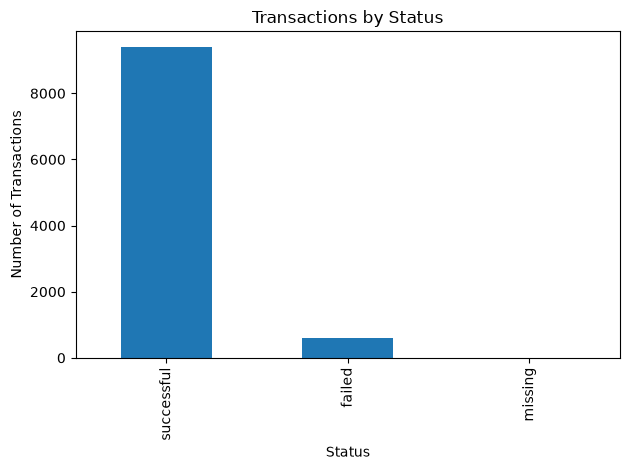

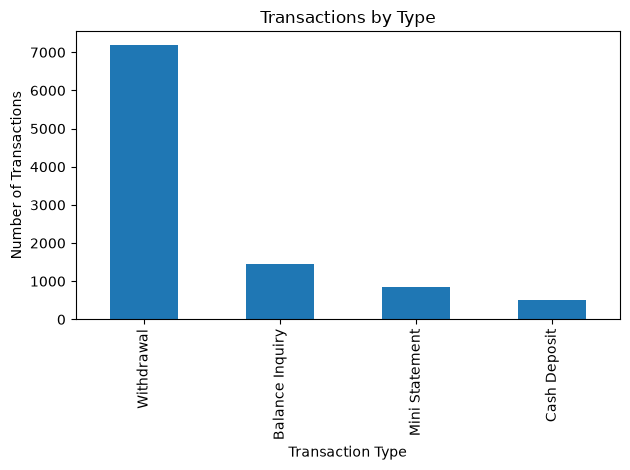

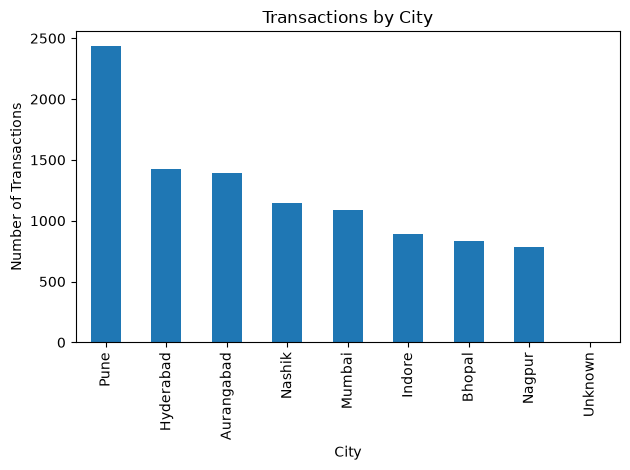

C:\Users\admin\Documents\ATM-Operations-Analytics\python\02_exploratory_data_analysis.py:127: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_time = pd.to_datetime(


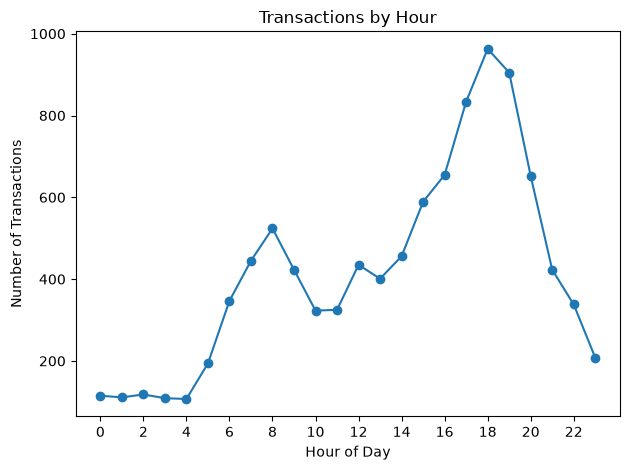


EDA completed.
Charts saved to: C:\Users\admin\Documents\ATM-Operations-Analytics\images


{'__name__': '__main__',
 '__doc__': '\nATM Operations & Cash Management Analytics\nFile: 02_exploratory_data_analysis.py\n\nPurpose:\n- Calculate transaction KPIs.\n- Summarize transaction status, type, city, and hour.\n- Generate charts for the project images folder.\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\admin\\Documents\\ATM-Operations-Analytics\\python\\02_exploratory_data_analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _fr

In [16]:

import runpy

runpy.run_path(str(eda_path), run_name="__main__")


In [17]:

anomaly_code = r'''"""
ATM Operations & Cash Management Analytics
File: 03_anomaly_analysis.py

Purpose:
- Flag unusually high transaction amounts for investigation.
- Identify ATMs with relatively high transaction failure rates.
- Export review files without changing the source data.

Note: Statistical flags are not proof of fraud or ATM malfunction.
"""

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
TRANSACTION_FLAGS_FILE = DATA_DIR / "anomaly_transaction_review.csv"
ATM_FLAGS_FILE = DATA_DIR / "anomaly_atm_failure_review.csv"


def find_sheet(sheets, keyword):
    for name, df in sheets.items():
        if keyword in name.lower():
            return df.copy()
    return None


def main():
    if not INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Cleaned workbook not found: {INPUT_FILE}. "
            "Run 01_data_cleaning.py first."
        )

    sheets = pd.read_excel(INPUT_FILE, sheet_name=None)
    transactions = find_sheet(sheets, "transaction")

    if transactions is None:
        raise ValueError(
            f"No transaction sheet found. Available sheets: {list(sheets)}"
        )

    transactions.columns = [
        str(c).strip().lower().replace(" ", "_").replace("-", "_")
        for c in transactions.columns
    ]

    required = {"amount", "status", "atm_id"}
    missing = required - set(transactions.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    transactions["amount"] = pd.to_numeric(
        transactions["amount"], errors="coerce"
    )
    transactions["status"] = (
        transactions["status"].astype("string").str.strip().str.lower()
    )

    # Analyze successful withdrawals separately because transaction
    # types may have different normal amount ranges.
    if "transaction_type" in transactions.columns:
        withdrawals = transactions[
            (transactions["transaction_type"].astype("string").str.strip().str.lower() == "withdrawal")
            & (transactions["status"] == "successful")
        ].copy()
    else:
        withdrawals = transactions[
            transactions["status"] == "successful"
        ].copy()

    valid_amounts = withdrawals["amount"].dropna()

    if len(valid_amounts) >= 2:
        mean_amount = valid_amounts.mean()
        std_amount = valid_amounts.std()
        threshold = mean_amount + 2 * std_amount

        withdrawals["review_reason"] = ""
        withdrawals.loc[
            withdrawals["amount"] > threshold, "review_reason"
        ] = "Amount above mean plus two standard deviations"

        amount_flags = withdrawals[
            withdrawals["review_reason"] != ""
        ].copy()

        print("\nHIGH-VALUE TRANSACTION REVIEW")
        print("=" * 40)
        print(f"Transactions assessed: {len(valid_amounts):,}")
        print(f"Average amount: {mean_amount:.2f}")
        print(f"Standard deviation: {std_amount:.2f}")
        print(f"Review threshold: {threshold:.2f}")
        print(f"Transactions flagged: {len(amount_flags):,}")

        amount_flags.to_csv(TRANSACTION_FLAGS_FILE, index=False)
        print("Transaction review saved:", TRANSACTION_FLAGS_FILE)
    else:
        print("Not enough valid amounts to calculate a review threshold.")

    # Calculate failure rates by ATM
    transactions["is_failed"] = (
        transactions["status"] == "failed"
    ).astype(int)

    atm_summary = transactions.dropna(subset=["atm_id"]).groupby(
        "atm_id"
    ).agg(
        total_transactions=("is_failed", "size"),
        failed_transactions=("is_failed", "sum")
    ).reset_index()

    atm_summary = atm_summary[
        atm_summary["total_transactions"] >= 50
    ].copy()

    atm_summary["failure_rate_percent"] = (
        atm_summary["failed_transactions"]
        / atm_summary["total_transactions"] * 100
    ).round(2)

    overall_failure_rate = (
        transactions["is_failed"].mean() * 100
        if len(transactions) else 0
    )

    atm_summary["overall_failure_rate_percent"] = round(
        overall_failure_rate, 2
    )
    atm_summary["above_overall_rate"] = (
        atm_summary["failure_rate_percent"] > overall_failure_rate
    )

    atm_summary = atm_summary.sort_values(
        "failure_rate_percent", ascending=False
    )

    atm_summary.to_csv(ATM_FLAGS_FILE, index=False)

    print("\nATM FAILURE-RATE REVIEW")
    print("=" * 40)
    print(f"Overall failure rate: {overall_failure_rate:.2f}%")
    print("ATMs assessed (minimum 50 transactions):", len(atm_summary))
    print("\nHighest failure-rate ATMs:")
    print(atm_summary.head(10).to_string(index=False))
    print("\nATM review saved:", ATM_FLAGS_FILE)


if __name__ == "__main__":
    main()
'''

anomaly_path = PYTHON_DIR / "03_anomaly_analysis.py"
anomaly_path.write_text(anomaly_code, encoding="utf-8")

print("Saved:", anomaly_path)
print("File size:", anomaly_path.stat().st_size, "bytes")


Saved: C:\Users\admin\Documents\ATM-Operations-Analytics\python\03_anomaly_analysis.py
File size: 4975 bytes


In [18]:

runpy.run_path(str(anomaly_path), run_name="__main__")



HIGH-VALUE TRANSACTION REVIEW
Transactions assessed: 6,778
Average amount: 4003.47
Standard deviation: 2913.57
Review threshold: 9830.61
Transactions flagged: 626
Transaction review saved: C:\Users\admin\Documents\ATM-Operations-Analytics\data\anomaly_transaction_review.csv


ValueError: cannot convert NA to integer

In [19]:

eda_code = r'''"""
ATM Operations & Cash Management Analytics
File: 02_exploratory_data_analysis.py

Purpose:
- Calculate transaction KPIs.
- Summarize transaction status, type, city, and hour.
- Generate charts for the project images folder.
"""

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = PROJECT_DIR / "images"

INPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)


def find_sheet(sheets, keyword):
    """Find a workbook sheet using a case-insensitive keyword."""
    for name, df in sheets.items():
        if keyword in name.lower():
            return df.copy()
    return None


def main():
    if not INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Cleaned workbook not found: {INPUT_FILE}. "
            "Run 01_data_cleaning.py first."
        )

    sheets = pd.read_excel(INPUT_FILE, sheet_name=None)

    # Locate the transaction sheet using its sheet name
    transactions = find_sheet(sheets, "transaction")
    if transactions is None:
        raise ValueError(
            f"No transaction sheet found. Available sheets: {list(sheets)}"
        )

    # Normalize column names in case the workbook uses mixed capitalization
    transactions.columns = [
        str(c).strip().lower().replace(" ", "_").replace("-", "_")
        for c in transactions.columns
    ]

    required = {"status", "amount"}
    missing = required - set(transactions.columns)
    if missing:
        raise ValueError(f"Missing required transaction columns: {missing}")

    transactions["status"] = (
        transactions["status"].astype("string").str.strip().str.lower()
    )
    transactions["amount"] = pd.to_numeric(
        transactions["amount"], errors="coerce"
    )

    total = len(transactions)
    successful = int((transactions["status"] == "successful").sum())
    failed = int((transactions["status"] == "failed").sum())
    success_rate = successful * 100 / total if total else 0

    print("\nATM TRANSACTION KPI SUMMARY")
    print("=" * 40)
    print(f"Total transactions: {total:,}")
    print(f"Successful transactions: {successful:,}")
    print(f"Failed transactions: {failed:,}")
    print(f"Success rate: {success_rate:.2f}%")

    # 1. Transaction status chart
    status_counts = transactions["status"].fillna("missing").value_counts()
    ax = status_counts.plot(kind="bar", title="Transactions by Status")
    ax.set_xlabel("Status")
    ax.set_ylabel("Number of Transactions")
    plt.tight_layout()
    plt.savefig(IMAGE_DIR / "eda_transaction_status.png", dpi=150)
    plt.show()
    plt.close()

    # 2. Transaction type chart, if available
    if "transaction_type" in transactions.columns:
        type_counts = transactions["transaction_type"].value_counts()
        ax = type_counts.plot(kind="bar", title="Transactions by Type")
        ax.set_xlabel("Transaction Type")
        ax.set_ylabel("Number of Transactions")
        plt.tight_layout()
        plt.savefig(IMAGE_DIR / "eda_transaction_types.png", dpi=150)
        plt.show()
        plt.close()

    # 3. City chart, if city exists in the transaction sheet
    # Otherwise, join the ATM sheet if it has the required fields.
    city_data = transactions.copy()
    if "city" not in city_data.columns:
        atms = find_sheet(sheets, "atm")
        if atms is not None:
            atms.columns = [
                str(c).strip().lower().replace(" ", "_").replace("-", "_")
                for c in atms.columns
            ]
            if {"atm_id", "city"}.issubset(atms.columns) and "atm_id" in city_data.columns:
                city_data = city_data.merge(
                    atms[["atm_id", "city"]].drop_duplicates("atm_id"),
                    on="atm_id",
                    how="left"
                )

    if "city" in city_data.columns:
        city_counts = city_data["city"].fillna("Unknown").value_counts()
        ax = city_counts.plot(kind="bar", title="Transactions by City")
        ax.set_xlabel("City")
        ax.set_ylabel("Number of Transactions")
        plt.tight_layout()
        plt.savefig(IMAGE_DIR / "eda_city_transactions.png", dpi=150)
        plt.show()
        plt.close()

    # 4. Hourly chart, if transaction_time exists
    if "transaction_time" in transactions.columns:
        parsed_time = pd.to_datetime(
            transactions["transaction_time"].astype("string"),
            errors="coerce"
        )
        hours = parsed_time.dt.hour
        if hours.notna().any():
            hourly_counts = hours.value_counts().sort_index()
            ax = hourly_counts.plot(
                kind="line", marker="o", title="Transactions by Hour"
            )
            ax.set_xlabel("Hour of Day")
            ax.set_ylabel("Number of Transactions")
            ax.set_xticks(range(0, 24, 2))
            plt.tight_layout()
            plt.savefig(IMAGE_DIR / "eda_hourly_transactions.png", dpi=150)
            plt.show()
            plt.close()

    # Export reusable summaries
    status_counts.rename_axis("status").reset_index(
        name="transaction_count"
    ).to_csv(DATA_DIR / "eda_status_summary.csv", index=False)

    if "transaction_type" in transactions.columns:
        transactions.groupby("transaction_type", dropna=False).agg(
            transaction_count=("amount", "size"),
            total_amount=("amount", "sum"),
            average_amount=("amount", "mean")
        ).round(2).reset_index().to_csv(
            DATA_DIR / "eda_transaction_type_summary.csv", index=False
        )

    print("\nEDA completed.")
    print("Charts saved to:", IMAGE_DIR)


if __name__ == "__main__":
    main()
'''

eda_path = PYTHON_DIR / "02_exploratory_data_analysis.py"
eda_path.write_text(eda_code, encoding="utf-8")

print("Saved:", eda_path)
print("File size:", eda_path.stat().st_size, "bytes")


Saved: C:\Users\admin\Documents\ATM-Operations-Analytics\python\02_exploratory_data_analysis.py
File size: 5913 bytes


In [20]:

anomaly_code = r'''"""
ATM Operations & Cash Management Analytics
File: 03_anomaly_analysis.py

Purpose:
- Flag unusually high transaction amounts for investigation.
- Identify ATMs with relatively high transaction failure rates.
- Export review files without changing the source data.

Note: Statistical flags are not proof of fraud or ATM malfunction.
"""

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_DIR / "data"

INPUT_FILE = DATA_DIR / "ATM_Analytics_Cleaned.xlsx"
TRANSACTION_FLAGS_FILE = DATA_DIR / "anomaly_transaction_review.csv"
ATM_FLAGS_FILE = DATA_DIR / "anomaly_atm_failure_review.csv"


def find_sheet(sheets, keyword):
    for name, df in sheets.items():
        if keyword in name.lower():
            return df.copy()
    return None


def main():
    if not INPUT_FILE.exists():
        raise FileNotFoundError(
            f"Cleaned workbook not found: {INPUT_FILE}. "
            "Run 01_data_cleaning.py first."
        )

    sheets = pd.read_excel(INPUT_FILE, sheet_name=None)
    transactions = find_sheet(sheets, "transaction")

    if transactions is None:
        raise ValueError(
            f"No transaction sheet found. Available sheets: {list(sheets)}"
        )

    transactions.columns = [
        str(c).strip().lower().replace(" ", "_").replace("-", "_")
        for c in transactions.columns
    ]

    required = {"amount", "status", "atm_id"}
    missing = required - set(transactions.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    transactions["amount"] = pd.to_numeric(
        transactions["amount"], errors="coerce"
    )
    transactions["status"] = (
        transactions["status"].astype("string").str.strip().str.lower()
    )

    # Analyze successful withdrawals separately because transaction
    # types may have different normal amount ranges.
    if "transaction_type" in transactions.columns:
        withdrawals = transactions[
            (transactions["transaction_type"].astype("string").str.strip().str.lower() == "withdrawal")
            & (transactions["status"] == "successful")
        ].copy()
    else:
        withdrawals = transactions[
            transactions["status"] == "successful"
        ].copy()

    valid_amounts = withdrawals["amount"].dropna()

    if len(valid_amounts) >= 2:
        mean_amount = valid_amounts.mean()
        std_amount = valid_amounts.std()
        threshold = mean_amount + 2 * std_amount

        withdrawals["review_reason"] = ""
        withdrawals.loc[
            withdrawals["amount"] > threshold, "review_reason"
        ] = "Amount above mean plus two standard deviations"

        amount_flags = withdrawals[
            withdrawals["review_reason"] != ""
        ].copy()

        print("\nHIGH-VALUE TRANSACTION REVIEW")
        print("=" * 40)
        print(f"Transactions assessed: {len(valid_amounts):,}")
        print(f"Average amount: {mean_amount:.2f}")
        print(f"Standard deviation: {std_amount:.2f}")
        print(f"Review threshold: {threshold:.2f}")
        print(f"Transactions flagged: {len(amount_flags):,}")

        amount_flags.to_csv(TRANSACTION_FLAGS_FILE, index=False)
        print("Transaction review saved:", TRANSACTION_FLAGS_FILE)
    else:
        print("Not enough valid amounts to calculate a review threshold.")

    # Calculate failure rates by ATM
    transactions["is_failed"] = (
        transactions["status"] == "failed"
    ).astype(int)

    atm_summary = transactions.dropna(subset=["atm_id"]).groupby(
        "atm_id"
    ).agg(
        total_transactions=("is_failed", "size"),
        failed_transactions=("is_failed", "sum")
    ).reset_index()

    atm_summary = atm_summary[
        atm_summary["total_transactions"] >= 50
    ].copy()

    atm_summary["failure_rate_percent"] = (
        atm_summary["failed_transactions"]
        / atm_summary["total_transactions"] * 100
    ).round(2)

    overall_failure_rate = (
        transactions["is_failed"].mean() * 100
        if len(transactions) else 0
    )

    atm_summary["overall_failure_rate_percent"] = round(
        overall_failure_rate, 2
    )
    atm_summary["above_overall_rate"] = (
        atm_summary["failure_rate_percent"] > overall_failure_rate
    )

    atm_summary = atm_summary.sort_values(
        "failure_rate_percent", ascending=False
    )

    atm_summary.to_csv(ATM_FLAGS_FILE, index=False)

    print("\nATM FAILURE-RATE REVIEW")
    print("=" * 40)
    print(f"Overall failure rate: {overall_failure_rate:.2f}%")
    print("ATMs assessed (minimum 50 transactions):", len(atm_summary))
    print("\nHighest failure-rate ATMs:")
    print(atm_summary.head(10).to_string(index=False))
    print("\nATM review saved:", ATM_FLAGS_FILE)


if __name__ == "__main__":
    main()
'''

anomaly_path = PYTHON_DIR / "03_anomaly_analysis.py"
anomaly_path.write_text(anomaly_code, encoding="utf-8")

print("Saved:", anomaly_path)
print("File size:", anomaly_path.stat().st_size, "bytes")


Saved: C:\Users\admin\Documents\ATM-Operations-Analytics\python\03_anomaly_analysis.py
File size: 4975 bytes


In [21]:

runpy.run_path(str(anomaly_path), run_name="__main__")



HIGH-VALUE TRANSACTION REVIEW
Transactions assessed: 6,778
Average amount: 4003.47
Standard deviation: 2913.57
Review threshold: 9830.61
Transactions flagged: 626
Transaction review saved: C:\Users\admin\Documents\ATM-Operations-Analytics\data\anomaly_transaction_review.csv


ValueError: cannot convert NA to integer

In [22]:
from pathlib import Path

CURRENT_DIR = Path.cwd()

# Works whether Jupyter is opened in the project folder or its python folder
PROJECT_DIR = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name.lower() == "python"
    else CURRENT_DIR
)

print("PROJECT FOLDER:", PROJECT_DIR)
print("\nROOT FILES AND FOLDERS:")
for item in sorted(PROJECT_DIR.iterdir()):
    print(f"{'[FOLDER]' if item.is_dir() else '[FILE]'} {item.name}")

for folder_name in ["python", "sql", "data", "images", "power-bi"]:
    folder = PROJECT_DIR / folder_name
    print(f"\n--- {folder_name}/ ---")

    if folder.exists():
        for item in sorted(folder.iterdir()):
            if item.is_file():
                print(f"{item.name}  |  {item.stat().st_size:,} bytes")
            else:
                print(f"{item.name}/")
    else:
        print("Folder not found")

PROJECT FOLDER: C:\Users\admin\Documents\ATM-Operations-Analytics

ROOT FILES AND FOLDERS:
[FOLDER] data
[FOLDER] images
[FOLDER] power bi
[FOLDER] python
[FILE] README.md
[FOLDER] sql

--- python/ ---
.ipynb_checkpoints/
01_data_cleaning.py  |  2,018 bytes
02_exploratory_data_analysis.py  |  5,913 bytes
03_anomaly_analysis.py  |  4,975 bytes
ATM_Data_Cleaning.ipynb  |  199,559 bytes

--- sql/ ---
01_data_validation.sql  |  1,920 bytes
02_transaction_analysis.sql  |  2,968 bytes
03_atm_performance.sql  |  3,180 bytes
04_cash_refill_analysis.sql  |  1,829 bytes
05_maintenance_analysis.sql  |  2,156 bytes

--- data/ ---
anomaly_transaction_review.csv  |  104,190 bytes
ATM_Analytics_Cleaned.xlsx  |  1,320,161 bytes
ATM_Analytics_PowerBI_Ready.xlsx  |  792,209 bytes
ATM_Operations_Cash_Management_Analytics (3).xlsx  |  1,847,777 bytes
data_quality_report.csv  |  273 bytes
eda_status_summary.csv  |  66 bytes
eda_transaction_type_summary.csv  |  209 bytes

--- images/ ---
eda_city_transactio

In [24]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()

print("power-bi exists:", (PROJECT_DIR / "power-bi").exists())
if (PROJECT_DIR / "power-bi").exists():
    for item in sorted((PROJECT_DIR / "power-bi").iterdir()):
        print(item.name)

power-bi exists: True


In [25]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()

print("POWER-BI FILES:")
for item in sorted((PROJECT_DIR / "power-bi").iterdir()):
    print(item.name)

print("\nGIT-RELATED FILES:")
for name in [".gitignore", ".gitattributes"]:
    print(f"{name}: {(PROJECT_DIR / name).exists()}")

print("\nLARGE FILES (over 10 MB):")
for item in PROJECT_DIR.rglob("*"):
    if item.is_file() and ".ipynb_checkpoints" not in str(item):
        if item.stat().st_size > 10 * 1024 * 1024:
            print(f"{item.relative_to(PROJECT_DIR)} — {item.stat().st_size / (1024*1024):.1f} MB")

POWER-BI FILES:

GIT-RELATED FILES:
.gitignore: False
.gitattributes: False

LARGE FILES (over 10 MB):


In [26]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()

gitignore_content = """# Python cache
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/
env/

# Jupyter temporary files
*.tmp

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Secrets and local configuration
.env
.env.*

# Power BI temporary/backup files
*.bak
*.tmp
"""

gitignore_path = PROJECT_DIR / ".gitignore"
gitignore_path.write_text(gitignore_content, encoding="utf-8")

print("Created:", gitignore_path)
print("\nContents:\n")
print(gitignore_path.read_text(encoding="utf-8"))

Created: C:\Users\admin\Documents\ATM-Operations-Analytics\.gitignore

Contents:

# Python cache
__pycache__/
*.py[cod]
.ipynb_checkpoints/

# Virtual environments
.venv/
venv/
env/

# Jupyter temporary files
*.tmp

# Operating system files
.DS_Store
Thumbs.db
desktop.ini

# Secrets and local configuration
.env
.env.*

# Power BI temporary/backup files
*.bak
*.tmp



In [27]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()
POWER_BI_DIR = PROJECT_DIR / "power-bi"
POWER_BI_DIR.mkdir(exist_ok=True)

dax_content = """-- ATM Operations Analytics: Starter DAX Measures
-- Update table and column names to match your Power BI data model.

Total Transactions =
COUNTROWS(Transactions)

Successful Transactions =
CALCULATE(
    [Total Transactions],
    Transactions[status] = "Successful"
)

Failed Transactions =
CALCULATE(
    [Total Transactions],
    Transactions[status] = "Failed"
)

Success Rate (%) =
DIVIDE(
    [Successful Transactions],
    [Total Transactions],
    0
) * 100

Failure Rate (%) =
DIVIDE(
    [Failed Transactions],
    [Total Transactions],
    0
) * 100
"""

guide_content = """# Power BI Dashboard — Build Status

The Power BI dashboard is planned but has not yet been built.

## Suggested dashboard pages

1. **Executive Overview** — total transactions, success rate, failure rate and transaction trends.
2. **ATM Reliability** — ATM-level failure rates, city comparison and maintenance downtime.
3. **Cash Operations** — cash refill patterns and operational monitoring.

## Starter measures

See `starter_measures.dax`.

**Important:** The DAX measures are templates. Confirm table and column names in the Power BI data model before using them.
"""

(POWER_BI_DIR / "starter_measures.dax").write_text(dax_content, encoding="utf-8")
(POWER_BI_DIR / "BUILD_GUIDE.md").write_text(guide_content, encoding="utf-8")

print("Created Power BI starter files:")
for item in sorted(POWER_BI_DIR.iterdir()):
    print(item.name)

Created Power BI starter files:
BUILD_GUIDE.md
starter_measures.dax


In [28]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name.lower() == "python" else Path.cwd()

required_files = [
    "README.md",
    ".gitignore",
    "python/01_data_cleaning.py",
    "python/02_exploratory_data_analysis.py",
    "python/03_anomaly_analysis.py",
    "python/ATM_Data_Cleaning.ipynb",
    "sql/01_data_validation.sql",
    "sql/02_transaction_analysis.sql",
    "sql/03_atm_performance.sql",
    "sql/04_cash_refill_analysis.sql",
    "sql/05_maintenance_analysis.sql",
    "power-bi/starter_measures.dax",
    "power-bi/BUILD_GUIDE.md",
]

print("FILE CHECK")
for name in required_files:
    path = PROJECT_DIR / name
    print(f"{'OK' if path.is_file() else 'MISSING'} - {name}")

print("\nFOLDER CHECK")
for name in ["data", "images", "python", "sql", "power-bi"]:
    print(f"{'OK' if (PROJECT_DIR / name).is_dir() else 'MISSING'} - {name}")

FILE CHECK
OK - README.md
OK - .gitignore
OK - python/01_data_cleaning.py
OK - python/02_exploratory_data_analysis.py
OK - python/03_anomaly_analysis.py
OK - python/ATM_Data_Cleaning.ipynb
OK - sql/01_data_validation.sql
OK - sql/02_transaction_analysis.sql
OK - sql/03_atm_performance.sql
OK - sql/04_cash_refill_analysis.sql
OK - sql/05_maintenance_analysis.sql
OK - power-bi/starter_measures.dax
OK - power-bi/BUILD_GUIDE.md

FOLDER CHECK
OK - data
OK - images
OK - python
OK - sql
OK - power-bi
